# Theory curves notebook

This notebook visualizes the theory and empirical residual curves for selected datasets.

In [1]:
from pathlib import Path
import pickle
import yaml

from adaptive_low_rank.datasets import load_dataset
from adaptive_low_rank.plotting import plot_theory_curves
from adaptive_low_rank.theory import compute_batchmax_alphas

repo_root = Path.cwd()
if not (repo_root / "results").exists():
    repo_root = repo_root.parent

def load_results(results_dir):
    results_dir = Path(results_dir)
    with (results_dir / "results.pkl").open("rb") as file:
        results = pickle.load(file)
    with (results_dir / "config.yml").open() as file:
        config = yaml.safe_load(file)
    return results, load_dataset(config=config)


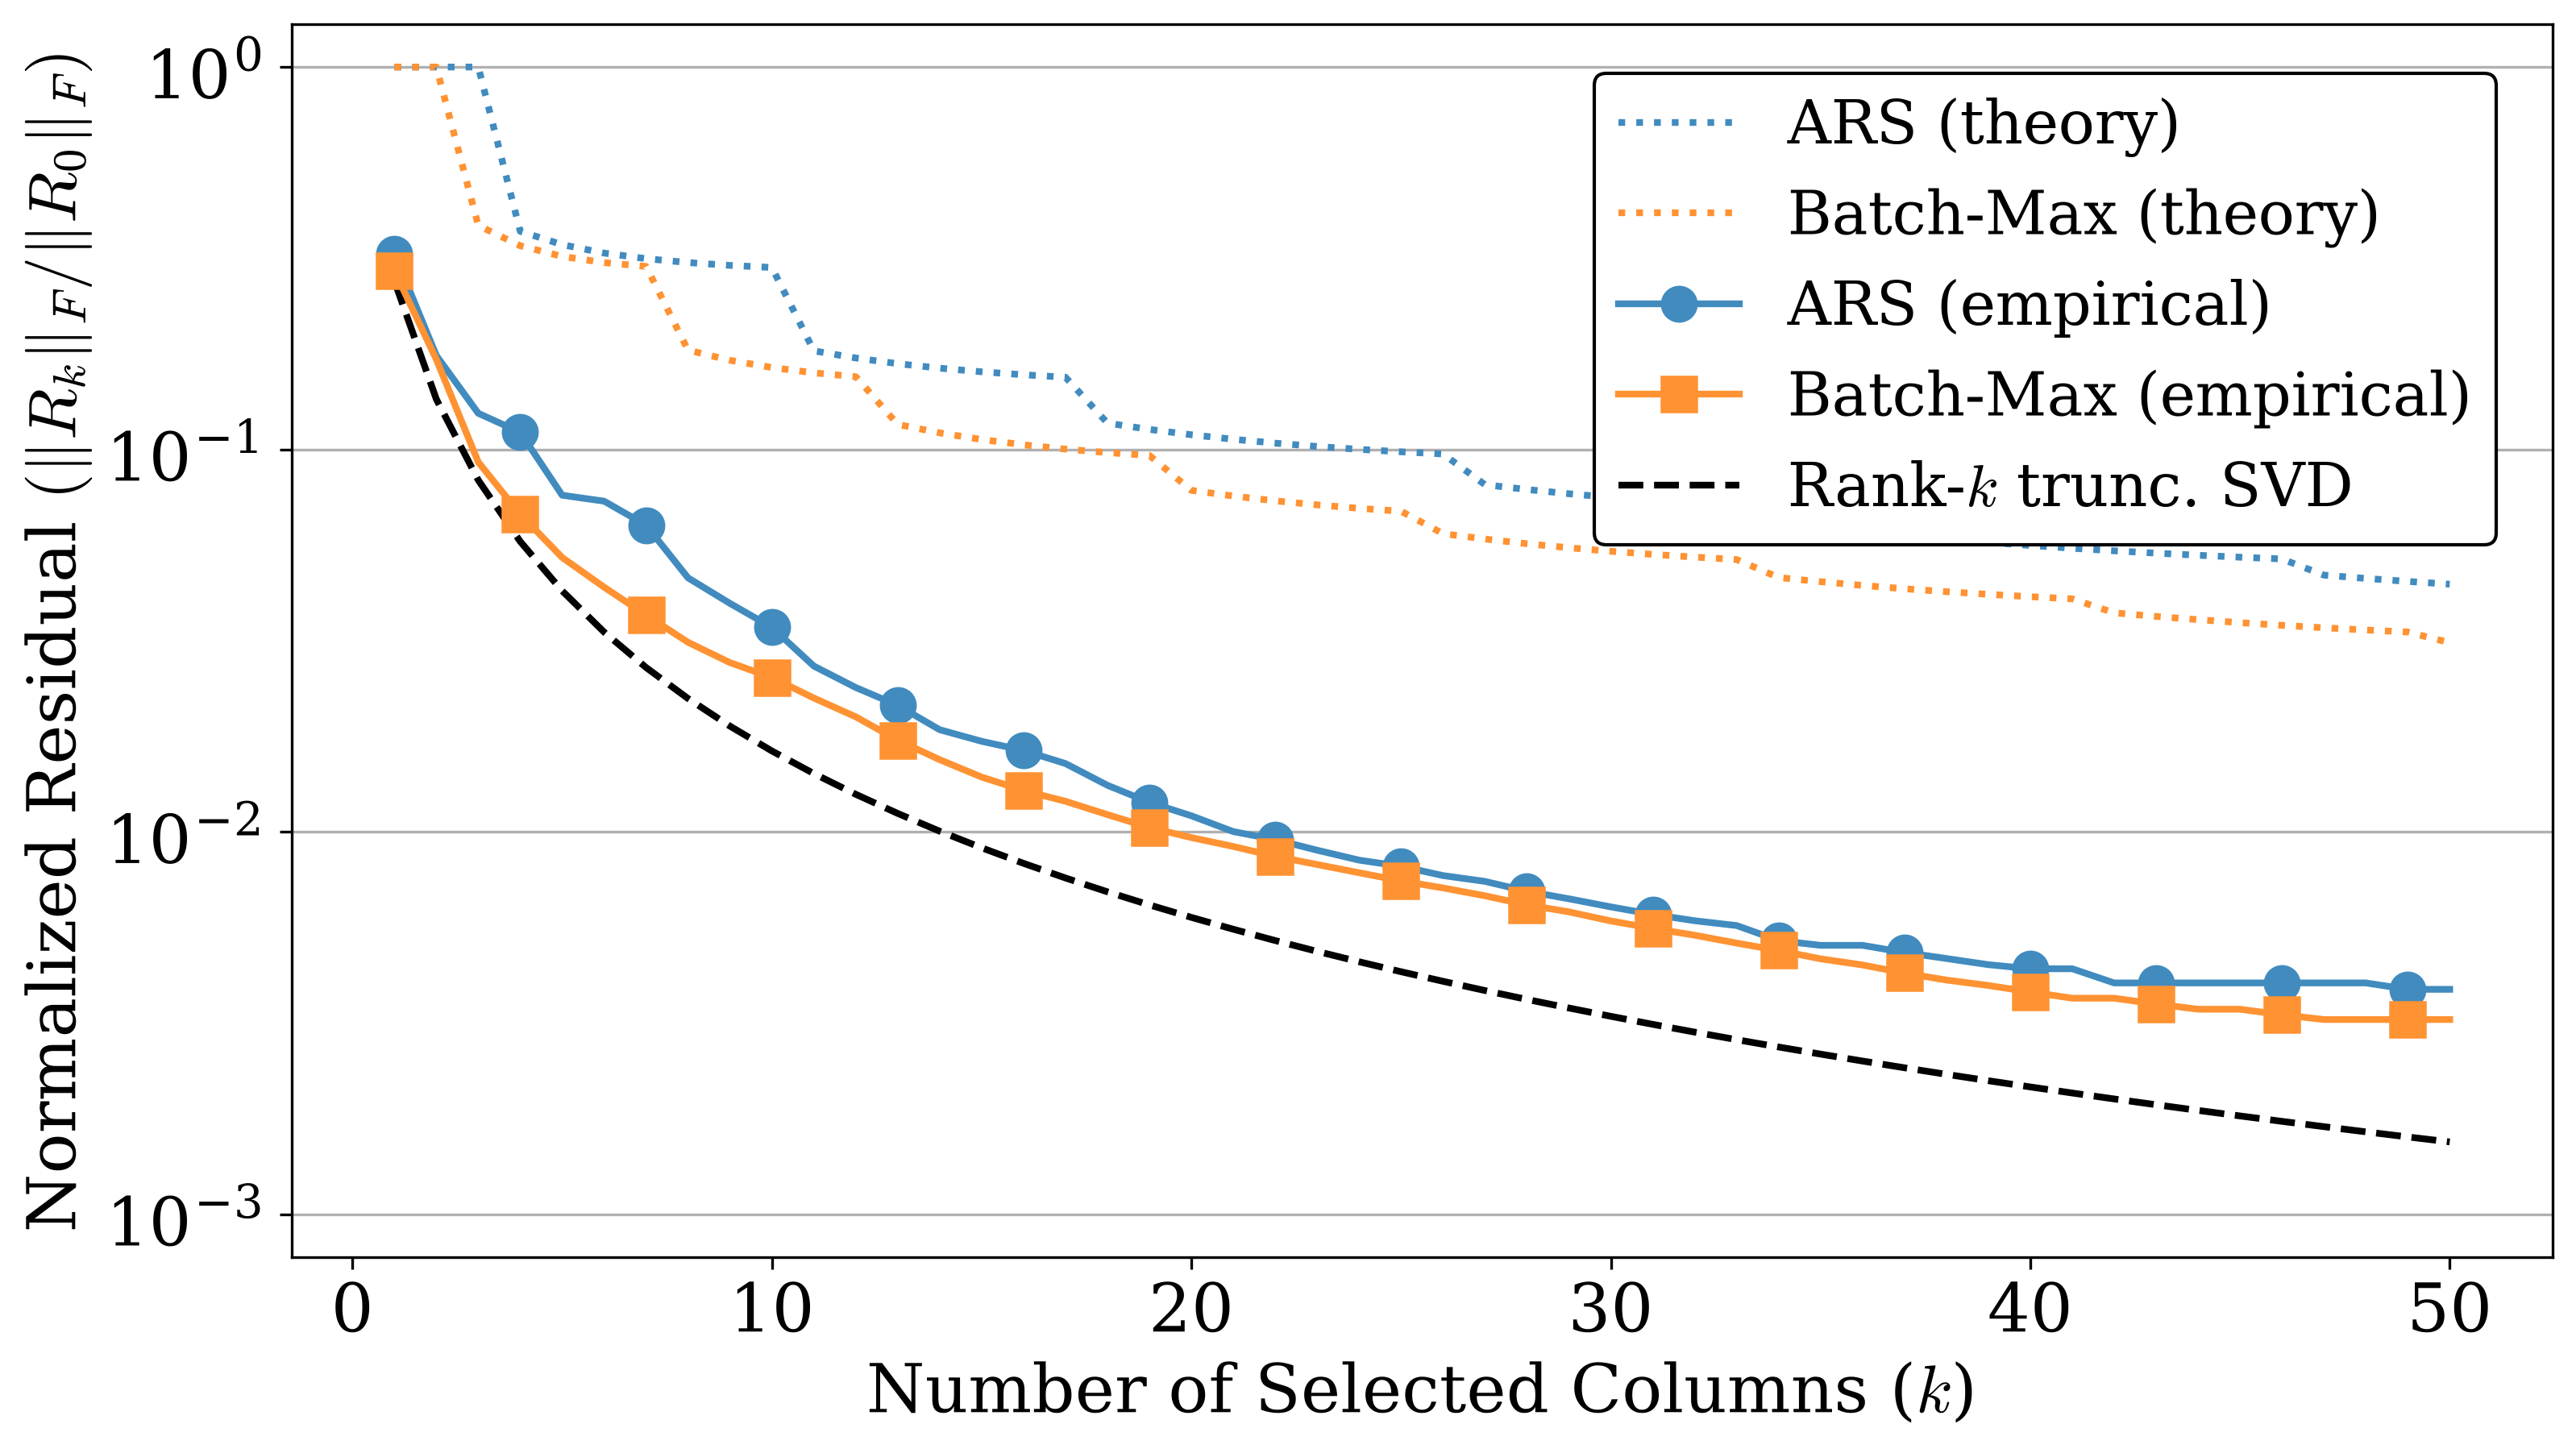

In [2]:
results, X = load_results(repo_root / "results" / "poly")
n_candidates = 10
max_k = 50
alphas = compute_batchmax_alphas(results, n_candidates=n_candidates)

fig, ax = plot_theory_curves(
    X,
    max_k=max_k,
    alphas=alphas,
    results=results,
    batchmax_n_candidates=n_candidates,
    output_path=repo_root / "figures" / "poly_theory.png",
    legend_loc="upper right",
)


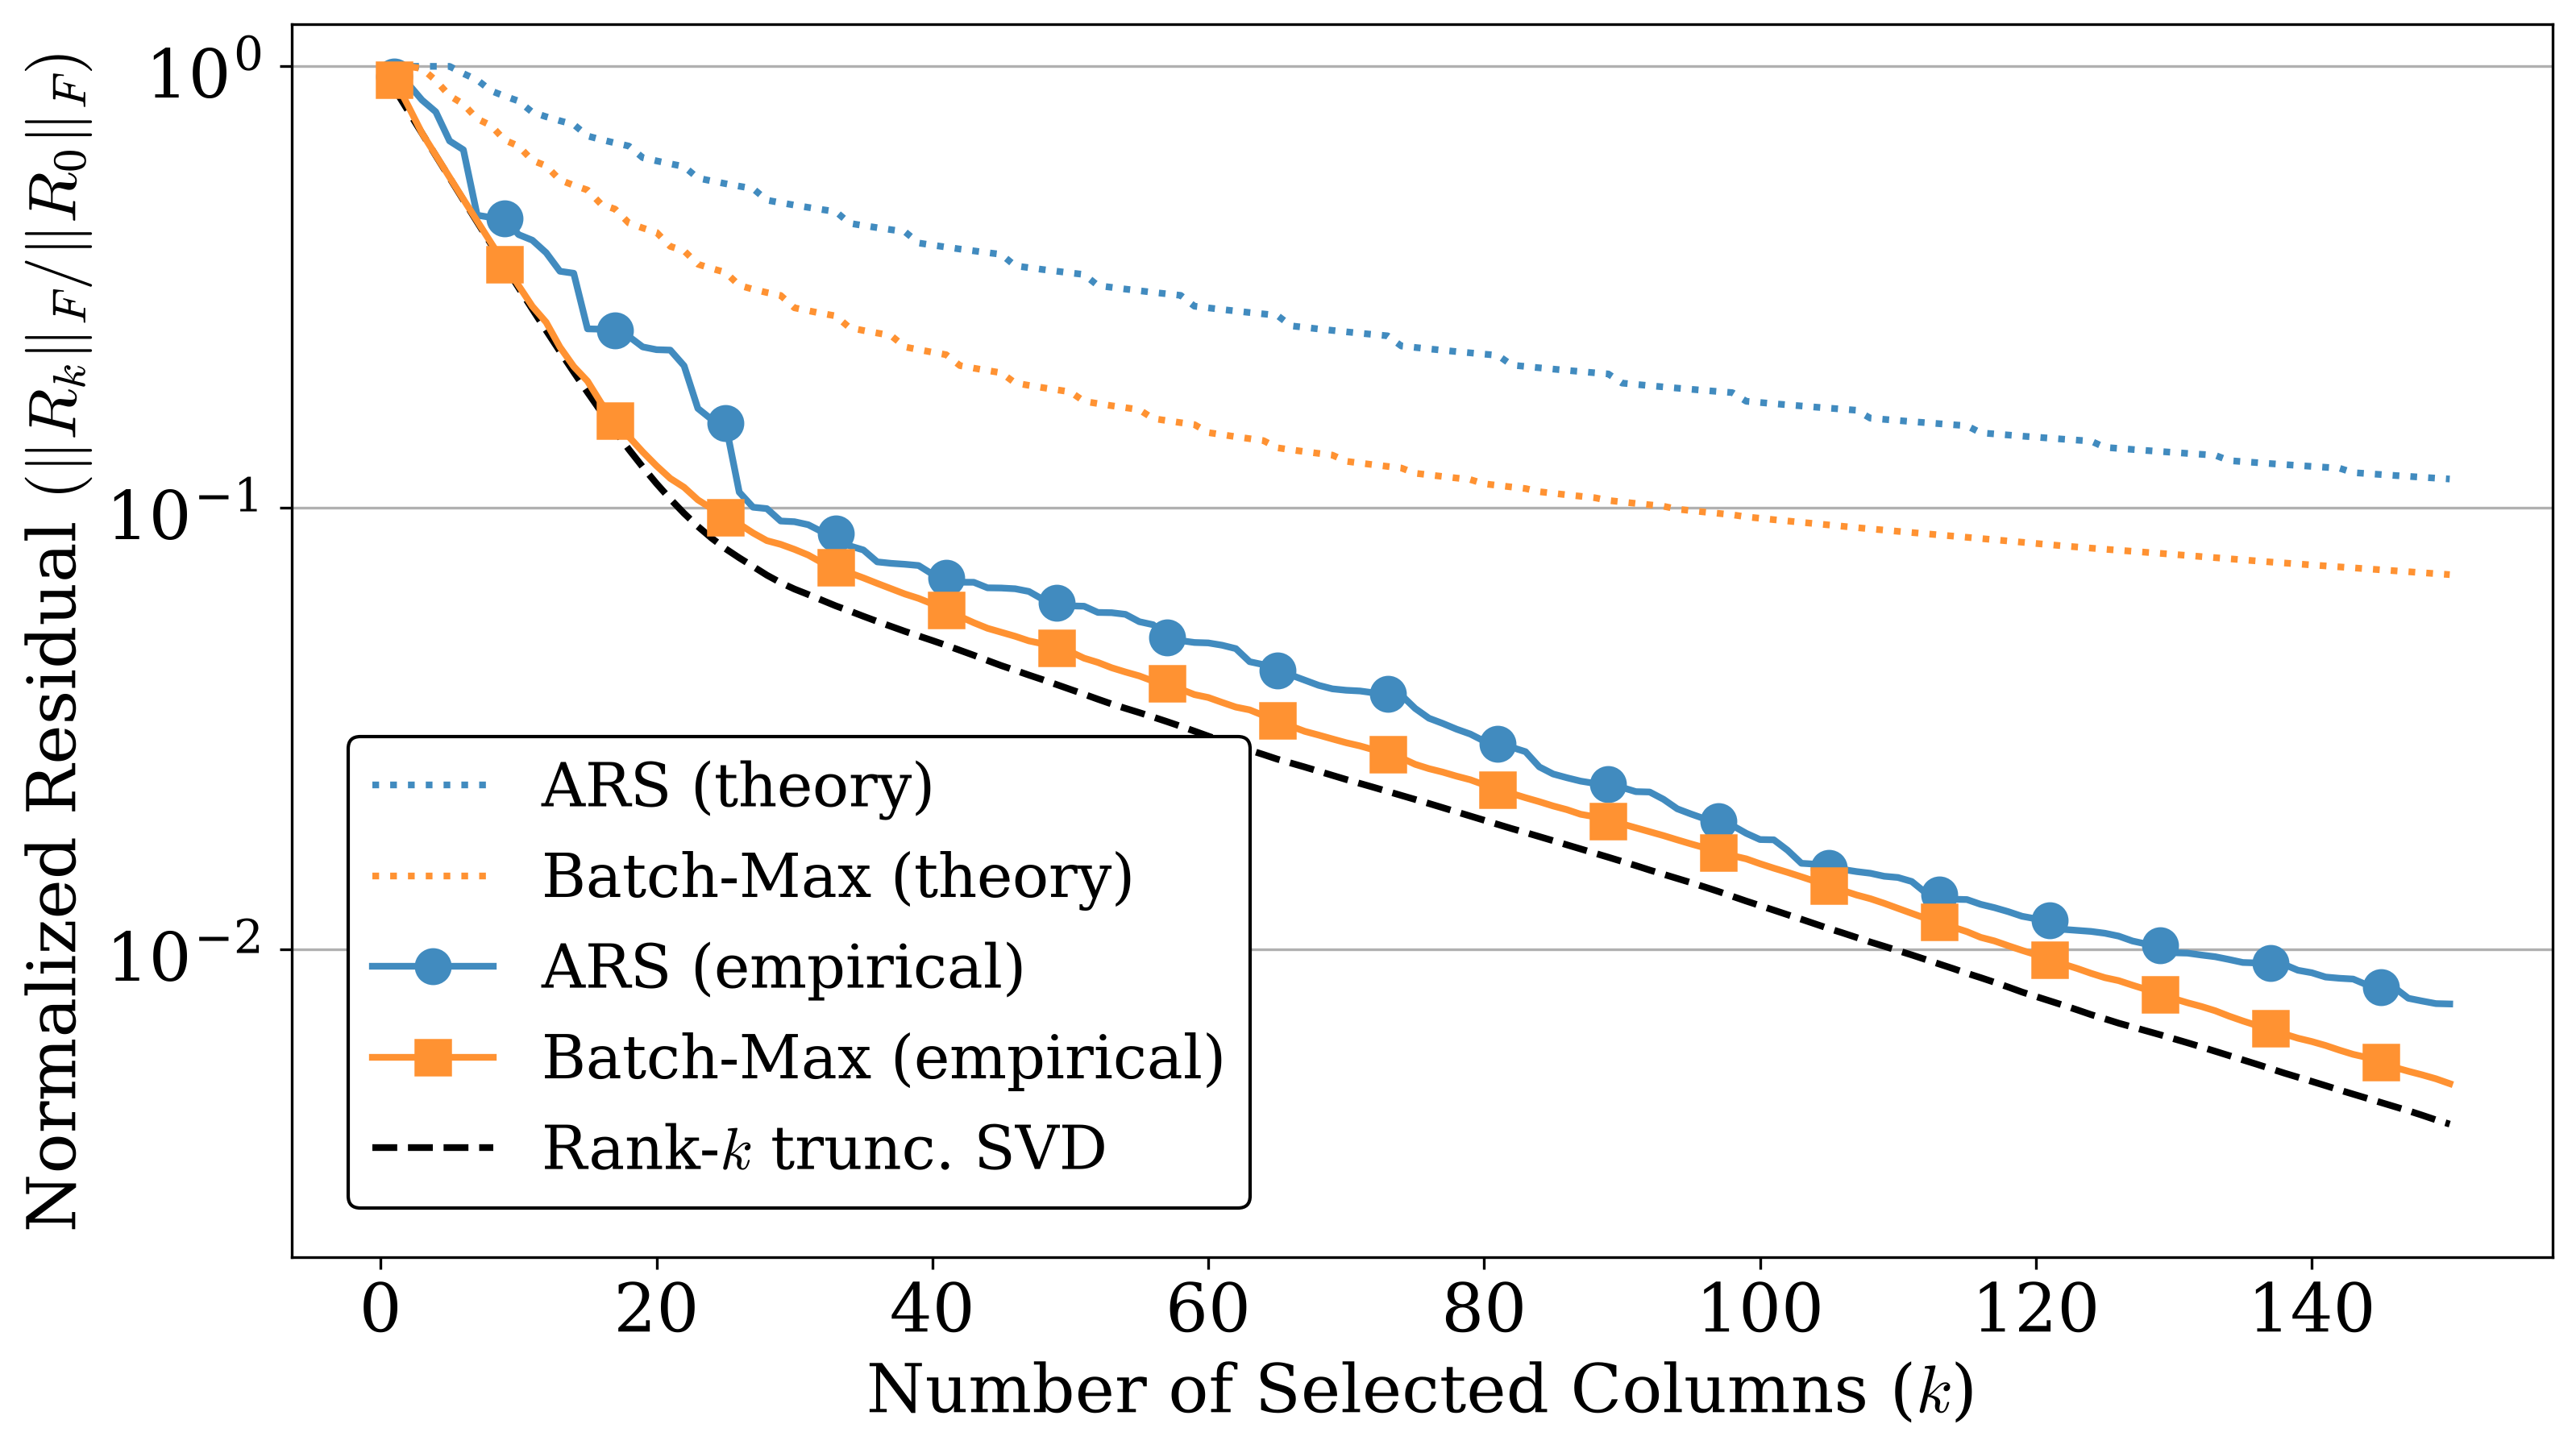

In [3]:
results, X = load_results(repo_root / "results" / "orthogonal_tubes")
n_candidates = 10
max_k = 150
alphas = compute_batchmax_alphas(results, n_candidates=n_candidates)

fig, ax = plot_theory_curves(
    X,
    max_k=max_k,
    alphas=alphas,
    results=results,
    batchmax_n_candidates=n_candidates,
    output_path=repo_root / "figures" / "orthogonal_tubes_theory.png",
)
